In [ ]:
import numpy as np
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix, classification_report, accuracy_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Prepare data

Download splitted training and validation dataset

In [ ]:
!gdown 1kW5mSxxzCyKvV3EWttHYDlPVeGaTPewu
!gdown 1kzE3mJWn565SwhYqpQAv3ZN33gY0pQwI
!gdown 1kfNLxm5niASSaw7GvcVTfXxUjaSJDzmW
!gdown 1kfYbOIF2RlLHH9zrf5TIMYCNtMeTors4

Downloading...
From: https://drive.google.com/uc?id=1kW5mSxxzCyKvV3EWttHYDlPVeGaTPewu
To: /content/X_valid.txt
100% 3.35M/3.35M [00:00<00:00, 194MB/s]
Downloading...
From: https://drive.google.com/uc?id=1kzE3mJWn565SwhYqpQAv3ZN33gY0pQwI
To: /content/X_train.txt
100% 13.3M/13.3M [00:00<00:00, 81.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1kfNLxm5niASSaw7GvcVTfXxUjaSJDzmW
To: /content/y_train.txt
100% 7.64k/7.64k [00:00<00:00, 25.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1kfYbOIF2RlLHH9zrf5TIMYCNtMeTors4
To: /content/y_valid.txt
100% 1.91k/1.91k [00:00<00:00, 8.62MB/s]


Download class_names.txt - mapping a category to an index

In [ ]:
!gdown 1TewzELPno6lG3v-file-MAx_W8Wf3b33

Downloading...
From: https://drive.google.com/uc?id=1TewzELPno6lG3v-file-MAx_W8Wf3b33
To: /content/class_names.txt
100% 97.0/97.0 [00:00<00:00, 335kB/s]


In [ ]:
X_train = []
with open('X_train.txt', 'r') as f:
    for line in f:
        X_train.append(line.strip())

X_valid = []
with open('X_valid.txt', 'r') as f:
    for line in f:
        X_valid.append(line.strip())

y_train = []
with open('y_train.txt', 'r') as f:
    for line in f:
        y_train.append(int(line.strip()))

y_valid = []
with open('y_valid.txt', 'r') as f:
    for line in f:
        y_valid.append(int(line.strip()))

class_names = []
with open('class_names.txt', 'r') as f:
    for line in f:
        class_names.append(line.strip())

In [ ]:
len(X_train), len(X_valid), len(y_train), len(y_valid)

(3820, 956, 3820, 956)

Load test dataset

In [ ]:
!gdown 17CnpRxPVN7sVSgvfm6yhWWUfhJe50KXa

Downloading...
From: https://drive.google.com/uc?id=17CnpRxPVN7sVSgvfm6yhWWUfhJe50KXa
To: /content/clean_data_test.csv
100% 3.96M/3.96M [00:00<00:00, 147MB/s]


In [ ]:
news_test_cleaned = pd.read_csv('clean_data_test.csv')
len(news_test_cleaned)

1090

In [ ]:
news_test_cleaned["title_description_content"] = (news_test_cleaned["title"] + " ") * 10 + (news_test_cleaned["description"] + " ") * 3  + news_test_cleaned["content"]

In [ ]:
X_test = news_test_cleaned["title_description_content"]
y_test = news_test_cleaned['category'].map({class_name: idx for idx, class_name in enumerate(class_names)}).to_numpy()
len(X_test), len(y_test)

(1090, 1090)

# Khảo sát trọng số tiêu đề, mô tả, nội dung

In [ ]:
!gdown 1kLcHOvsnOwuTgZZIOnOpK8p2AKUprQ7x

Downloading...
From: https://drive.google.com/uc?id=1kLcHOvsnOwuTgZZIOnOpK8p2AKUprQ7x
To: /content/2024_05_05_news_600_samples_each_category.csv
100% 13.8M/13.8M [00:00<00:00, 129MB/s]


In [ ]:
!gdown 1TewzELPno6lG3v-file-MAx_W8Wf3b33

Downloading...
From: https://drive.google.com/uc?id=1TewzELPno6lG3v-file-MAx_W8Wf3b33
To: /content/class_names.txt
100% 98.0/98.0 [00:00<00:00, 446kB/s]


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix, classification_report
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score

In [ ]:
class_names = []
with open('class_names.txt', 'r') as f:
    for line in f:
        class_names.append(line.strip())

In [ ]:
def class_name_to_id(class_name):
    return list(class_names).index(class_name)

In [ ]:
def hyperparameter_analytics(hyperparameter_values):
    news_600_sample = pd.read_csv('2024_05_05_news_600_samples_each_category.csv')
    news_600_sample["title_description_content"] = (news_600_sample["title"] + " ") * hyperparameter_values[0] + (news_600_sample["description"] + " ") * hyperparameter_values[1]  + news_600_sample["content"]

    news_600_sample['category_id'] = news_600_sample['category'].apply(class_name_to_id)
    documents = news_600_sample.title_description_content.to_list()
    categories_id = news_600_sample.category_id.to_list()

    X_train, X_valid, y_train, y_valid = train_test_split(documents, categories_id, test_size=0.2, stratify=categories_id, random_state=42)

    with open('X_train.txt', 'w') as f:
        for item in X_train:
            f.write("%s\n" % item)

    with open('X_valid.txt', 'w') as f:
        for item in X_valid:
            f.write("%s\n" % item)

    with open('y_train.txt', 'w') as f:
        for item in y_train:
            f.write("%s\n" % item)

    with open('y_valid.txt', 'w') as f:
        for item in y_valid:
            f.write("%s\n" % item)

    X_train = []
    with open('X_train.txt', 'r') as f:
        for line in f:
            X_train.append(line.strip())

    X_valid = []
    with open('X_valid.txt', 'r') as f:
        for line in f:
            X_valid.append(line.strip())

    y_train = []
    with open('y_train.txt', 'r') as f:
        for line in f:
            y_train.append(int(line.strip()))

    y_valid = []
    with open('y_valid.txt', 'r') as f:
        for line in f:
            y_valid.append(int(line.strip()))

    featurizer = TfidfVectorizer(min_df=3)

    X_train_feat = featurizer.fit_transform(X_train)
    X_valid_feat = featurizer.transform(X_valid)

    print(X_train_feat.shape)
    print(X_valid_feat.shape)

    print("Training on Multinomial Naive bayes ...")

    clf_nb = MultinomialNB()
    clf_nb.fit(X_train_feat, y_train)
    y_pred = clf_nb.predict(X_valid_feat)
    # calculate f1 score
    f1 = f1_score(y_valid, y_pred, average='weighted')
    print(f"f1 score: {f1:.4f}")
    acc = accuracy_score(y_valid, y_pred)
    print(f"accuracy: {acc:.4f}")

    df_hyperp.loc[len(df_hyperp)] = [hyperparameter_values, "Multinomial Naive Bayes", acc, f1]

    print("Training on Random Forest Classifier...")
    clf_rdforest = RandomForestClassifier(n_estimators=100, criterion="gini", random_state=42)  # Set the number of trees as 100
    clf_rdforest.fit(X_train_feat, y_train)
    y_pred = clf_rdforest.predict(X_valid_feat)
    # calculate f1 score
    f1 = f1_score(y_valid, y_pred, average='weighted')
    print(f"f1 score: {f1:.4f}")
    # calculate accuracy
    acc = accuracy_score(y_valid, y_pred)
    print(f"accuracy: {acc:.4f}")
    df_hyperp.loc[len(df_hyperp)] = [hyperparameter_values, "Random Forest Classifier", acc, f1]

In [ ]:
df_hyperp = pd.DataFrame(columns=['Hyperparameter_values', 'Model', "accuracy", "f1_score"])
for p1 in range(10, 1, -1):
    for p2 in range(1, p1 + 1):
        p3 = 1
        if (p1 == 10 and p2 == 3 and p3 == 1): continue
        print(f"p1: {p1}, p2: {p2}, p3: {p3}")
        hyperparameter_analytics([p1, p2, p3])

p1: 10, p2: 1, p3: 1
(3820, 16448)
(956, 16448)
Training on Multinomial Naive bayes ...
f1 score: 0.9086
accuracy: 0.9100
Training on Random Forest Classifier...
f1 score: 0.8997
accuracy: 0.9017
p1: 10, p2: 2, p3: 1
(3820, 16448)
(956, 16448)
Training on Multinomial Naive bayes ...
f1 score: 0.9067
accuracy: 0.9079
Training on Random Forest Classifier...
f1 score: 0.9107
accuracy: 0.9132
p1: 10, p2: 4, p3: 1
(3820, 16448)
(956, 16448)
Training on Multinomial Naive bayes ...
f1 score: 0.9077
accuracy: 0.9090
Training on Random Forest Classifier...
f1 score: 0.8965
accuracy: 0.8996
p1: 10, p2: 5, p3: 1


In [ ]:
df_hyperp.sort_values(by=['f1_score'], ascending=False)

,Hyperparameter_values,Model,accuracy,f1_score,roc_auc_score
83,"[6, 6, 1]",Random Forest Classifier,0.922594,0.920334,"{0: 0.9898325358851674, 1: 0.9731858054226477,..."
27,"[9, 2, 1]",Random Forest Classifier,0.920502,0.918514,"{0: 0.985067783094099, 1: 0.9684210526315788, ..."
91,"[5, 4, 1]",Random Forest Classifier,0.919456,0.917575,"{0: 0.9904306220095694, 1: 0.9642543859649122,..."
99,"[4, 3, 1]",Random Forest Classifier,0.919456,0.917100,"{0: 0.9910287081339714, 1: 0.9713915470494419,..."
25,"[9, 1, 1]",Random Forest Classifier,0.918410,0.916054,"{0: 0.9910287081339714, 1: 0.9749601275917066,..."
...,...,...,...,...,...
58,"[7, 1, 1]",Multinomial Naive Bayes,0.898536,0.895865,"{0: 0.9856658692185007, 1: 0.9630582137161084,..."
72,"[6, 1, 1]",Multinomial Naive Bayes,0.898536,0.895763,"{0: 0.9856658692185007, 1: 0.9630582137161084,..."
100,"[4, 4, 1]",Multinomial Naive Bayes,0.898536,0.895739,"{0: 0.9856658692185007, 1: 0.9594896331738437,..."
24,"[9, 1, 1]",Multinomial Naive Bayes,0.897490,0.894929,"{0: 0.985067783094099, 1: 0.9594896331738437, ..."


# Khảo sát TF-IDF

Với ý tưởng loại bỏ bớt những từ xuất hiện nhiều qua các bài báo - những từ có **Document Frequency** cao. Có thể những từ này sẽ là những stop words mới mà nhóm cần xem xét để loại bỏ.

In [ ]:
len(X_train), len(X_valid), len(y_train), len(y_valid)

(3820, 956, 3820, 956)

In [ ]:
featurizer = TfidfVectorizer(min_df=3)

X_train_feat = featurizer.fit_transform(X_train)
X_valid_feat = featurizer.transform(X_valid)

In [ ]:
voca_dict = featurizer.vocabulary_
len(voca_dict)

16455

In [ ]:
feature_names = featurizer.get_feature_names_out()
feature_names

array(['00', '007', '01', ..., 'ứng_xử', 'ửng', 'ỷ_lại'], dtype=object)

In [ ]:
idf_values = featurizer.idf_
idf_values

array([6.07021362, 7.86197309, 5.08938436, ..., 5.78253154, 7.63882954,
       6.94568235])

Text(0.5, 1.0, 'Inverse Document Frequency Distribution')

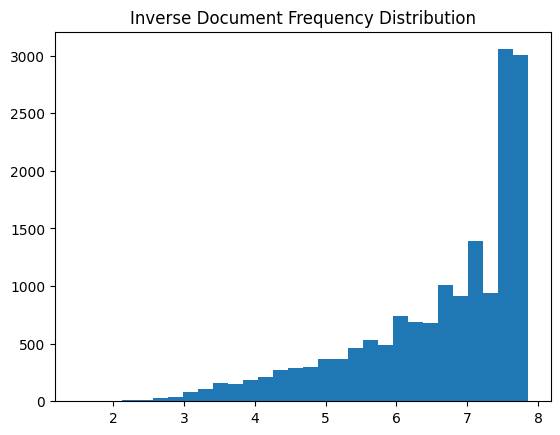

In [ ]:
plt.hist(idf_values, bins=30)
plt.title('Inverse Document Frequency Distribution')

Dựa vào đồ thị, những từ có *DF - Document Frequency* cao tương ứng với *IDF-Inverse Document Frequency* thấp.

Quan sát, ta có thể thử nghiệm, xem xét các thêm các từ có `IDF < thresh`. Với thresh ta có thể thử nghiệm với những giá trị nhỏ hơn 2.5

In [ ]:
def applyModel(model, stopwords):
  featurizer = TfidfVectorizer(min_df=3, stop_words=stopwords)
  X_train_feat = featurizer.fit_transform(X_train)

  voca_dict = featurizer.vocabulary_
  print('Length of voca:', len(voca_dict))

  X_valid_feat = featurizer.transform(X_valid)
  np.random.seed(42)
  # model = MultinomialNB(alpha=0.25, fit_prior=True)
  model.fit(X_train_feat, y_train)

  score = model.score(X_valid_feat, y_valid)
  print('Model score:', score)
  return score

In [ ]:
def tune_tfidf(model, thresh):
  idx_of_consider_stopwords = np.where(idf_values < thresh)
  consider_stopwords = [ feature_names[idx] for idx in idx_of_consider_stopwords ]
  consider_stopwords = consider_stopwords[0]
  print('Considered stopwords: ')
  print(consider_stopwords)
  return applyModel(model, consider_stopwords.tolist())

## 1. Khảo sát với model Multinomial Naive Bayes

In [ ]:
threshs = np.linspace(2, 2.5, 10)

scores = []
model_list = []
for thresh in threshs:
  print('--' * 20)
  print("Thresh:", thresh)
  model = MultinomialNB(alpha=0.25, fit_prior=True)
  score = tune_tfidf(model, thresh)
  model_list.append(model)
  scores.append(score)

----------------------------------------
Thresh: 2.0
Considered stopwords: 
['hai' 'nam' 'đi' 'đầu' 'ảnh']
Length of voca: 16450
Model score: 0.9205020920502092
----------------------------------------
Thresh: 2.0555555555555554
Considered stopwords: 
['hai' 'hàng' 'nam' 'đi' 'đầu' 'ảnh']
Length of voca: 16449
Model score: 0.9205020920502092
----------------------------------------
Thresh: 2.111111111111111
Considered stopwords: 
['giúp' 'hai' 'hàng' 'nam' 'đi' 'đầu' 'ảnh']
Length of voca: 16448
Model score: 0.9205020920502092
----------------------------------------
Thresh: 2.1666666666666665
Considered stopwords: 
['giúp' 'hai' 'hàng' 'nam' 'đi' 'đầu' 'ảnh']
Length of voca: 16448
Model score: 0.9205020920502092
----------------------------------------
Thresh: 2.2222222222222223
Considered stopwords: 
['giúp' 'hai' 'hàng' 'nam' 'việt' 'đi' 'đầu' 'ảnh']
Length of voca: 16447
Model score: 0.9205020920502092
----------------------------------------
Thresh: 2.2777777777777777
Considered s

Đã có sự cải thiện khi chúng ta xem xét những từ phổ biến `['hai' 'nam' 'đi' 'đầu' 'ảnh']` là stop word

Độ chính xác đã tăng từ `90.73%` lên `92.05%`.

## 2. Khảo sát với model Random Forest:

In [ ]:
threshs = np.linspace(2, 2.5, 10)

scores = []
model_list = []
for thresh in threshs:
  print('--' * 20)
  print("Thresh:", thresh)

  model = RandomForestClassifier(n_estimators=200, criterion="gini", max_depth=None, bootstrap=False, random_state=42)  # Set the number of trees as 100
  score = tune_tfidf(model, thresh)
  model_list.append(model)
  scores.append(score)

----------------------------------------
Thresh: 2.0
Considered stopwords: 
['hai' 'nam' 'đi' 'đầu' 'ảnh']
Length of voca: 16450
Model score: 0.9341004184100419
----------------------------------------
Thresh: 2.0555555555555554
Considered stopwords: 
['hai' 'hàng' 'nam' 'đi' 'đầu' 'ảnh']
Length of voca: 16449
Model score: 0.9267782426778243
----------------------------------------
Thresh: 2.111111111111111
Considered stopwords: 
['giúp' 'hai' 'hàng' 'nam' 'đi' 'đầu' 'ảnh']
Length of voca: 16448
Model score: 0.9372384937238494
----------------------------------------
Thresh: 2.1666666666666665
Considered stopwords: 
['giúp' 'hai' 'hàng' 'nam' 'đi' 'đầu' 'ảnh']
Length of voca: 16448
Model score: 0.9372384937238494
----------------------------------------
Thresh: 2.2222222222222223
Considered stopwords: 
['giúp' 'hai' 'hàng' 'nam' 'việt' 'đi' 'đầu' 'ảnh']
Length of voca: 16447
Model score: 0.9309623430962343
----------------------------------------
Thresh: 2.2777777777777777
Considered s

# Khảo sát mô hình

In [ ]:
def plot_cm(confusion_mt, class_names):
  df_confusion_mt = pd.DataFrame(confusion_mt, index=class_names, columns=class_names)
  ax = sn.heatmap(df_confusion_mt, annot=True, fmt='g', cmap='Blues')
  ax.set_xlabel("Predicted", fontsize=12)
  ax.set_xticklabels(class_names, rotation=45)
  ax.set_ylabel("Target", fontsize=12)

## Multinomial Naive Bayes

Extract feature by using `TfidfVectorizer`

In [ ]:
featurizer = TfidfVectorizer(min_df=3)

X_train_feat = featurizer.fit_transform(X_train)
X_valid_feat = featurizer.transform(X_valid)

In [ ]:
voca_dict = featurizer.vocabulary_
len(voca_dict)

16455

Finetune hyperparameters

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', MultinomialNB())
])

parameters = {
    'clf__alpha': [0.1, 0.25, 0.5, 0.75, 1.0],
    'clf__fit_prior': [True, False]
}

grid_search_tune = GridSearchCV(pipeline, parameters, cv=4, n_jobs=-1, verbose=2)

grid_search_tune.fit(X_train, y_train)

# Evaluate
y_pred = grid_search_tune.predict(X_valid)

# Calculate f1 score
f1 = f1_score(y_valid, y_pred, average='weighted')
print(f"F1 Score: {f1:.4f}")

# Calculate accuracy
acc = accuracy_score(y_valid, y_pred)
print(f"Accuracy: {acc:.4f}")


Fitting 4 folds for each of 10 candidates, totalling 40 fits
F1 Score: 0.9175
Accuracy: 0.9184


Best hyperparameters

In [ ]:
grid_search_tune.best_params_

{'clf__alpha': 0.25, 'clf__fit_prior': True}

Test the best model on the test dataset

In [ ]:
y_test_pred = grid_search_tune.predict(X_test)
print(classification_report(y_test, y_test_pred, target_names=class_names))

              precision    recall  f1-score   support

    Giải trí       0.94      0.94      0.94       127
    Đời sống       0.78      0.73      0.75       132
    Thể thao       0.96      0.97      0.97       139
    Thế giới       0.98      0.86      0.92       139
     Du lịch       0.82      0.92      0.86       132
   Pháp luật       0.93      0.94      0.94       145
    Giáo dục       0.91      0.95      0.93       129
    Sức khỏe       0.93      0.95      0.94       147

    accuracy                           0.91      1090
   macro avg       0.91      0.91      0.91      1090
weighted avg       0.91      0.91      0.91      1090



In [ ]:
# Calculate f1 score
f1 = f1_score(y_test, y_test_pred, average='weighted')
print(f"F1 Score: {f1:.4f}")

# Calculate accuracy
acc = accuracy_score(y_test, y_test_pred)
print(f"Accuracy: {acc:.4f}")

F1 Score: 0.9069
Accuracy: 0.9073


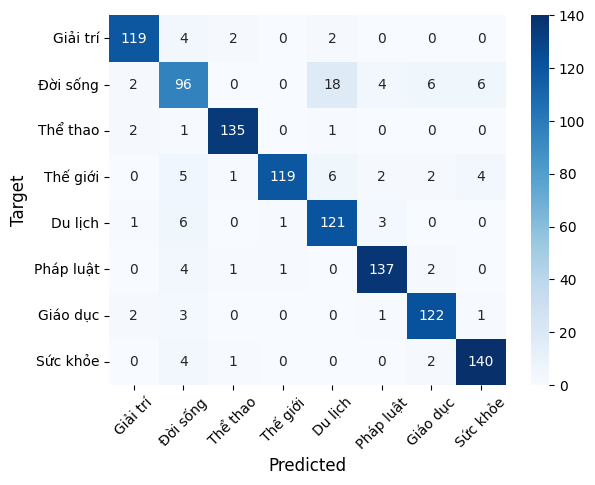

In [ ]:
plot_cm(confusion_matrix(y_test, y_test_pred), class_names)

## Random Forest

### Prepare data

**Load train & validation data**

In [ ]:
!gdown 1l9NPdoPxtuev4iMzyJLT-ikHAR0xCJrz # download classes.txt

# download splitted dataset
!gdown 1kW5mSxxzCyKvV3EWttHYDlPVeGaTPewu
!gdown 1kzE3mJWn565SwhYqpQAv3ZN33gY0pQwI
!gdown 1kfNLxm5niASSaw7GvcVTfXxUjaSJDzmW
!gdown 1kfYbOIF2RlLHH9zrf5TIMYCNtMeTors4

Downloading...
From: https://drive.google.com/uc?id=1l9NPdoPxtuev4iMzyJLT-ikHAR0xCJrz
To: /content/class_names.txt
100% 98.0/98.0 [00:00<00:00, 400kB/s]
Downloading...
From: https://drive.google.com/uc?id=1kW5mSxxzCyKvV3EWttHYDlPVeGaTPewu
To: /content/X_valid.txt
100% 3.35M/3.35M [00:00<00:00, 178MB/s]
Downloading...
From: https://drive.google.com/uc?id=1kzE3mJWn565SwhYqpQAv3ZN33gY0pQwI
To: /content/X_train.txt
100% 13.3M/13.3M [00:00<00:00, 96.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1kfNLxm5niASSaw7GvcVTfXxUjaSJDzmW
To: /content/y_train.txt
100% 7.64k/7.64k [00:00<00:00, 16.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1kfYbOIF2RlLHH9zrf5TIMYCNtMeTors4
To: /content/y_valid.txt
100% 1.91k/1.91k [00:00<00:00, 6.40MB/s]


**Load test data**

In [ ]:
!gdown 17CnpRxPVN7sVSgvfm6yhWWUfhJe50KXa

Downloading...
From: https://drive.google.com/uc?id=17CnpRxPVN7sVSgvfm6yhWWUfhJe50KXa
To: /content/clean_data_test (1).csv
100% 3.96M/3.96M [00:00<00:00, 69.8MB/s]


train & valid data

In [ ]:
X_train = []
with open('X_train.txt', 'r') as f:
    for line in f:
        X_train.append(line.strip())

X_valid = []
with open('X_valid.txt', 'r') as f:
    for line in f:
        X_valid.append(line.strip())

y_train = []
with open('y_train.txt', 'r') as f:
    for line in f:
        y_train.append(int(line.strip()))

y_valid = []
with open('y_valid.txt', 'r') as f:
    for line in f:
        y_valid.append(int(line.strip()))

class_names = []
with open('class_names.txt', 'r') as f:
    for line in f:
        class_names.append(line.strip())

test data

In [ ]:
news_test_cleaned = pd.read_csv('clean_data_test.csv')

In [ ]:
news_test_cleaned["title_description_content"] = (news_test_cleaned["title"] + " ") * 10 + (news_test_cleaned["description"] + " ") * 3  + news_test_cleaned["content"]

In [ ]:
vectorizer = TfidfVectorizer(min_df=3)
X_train_features = vectorizer.fit_transform(X_train)
X_valid_features = vectorizer.transform(X_valid)
X_test_features = vectorizer.transform(news_test_cleaned["title_description_content"])

In [ ]:
voca_dict = vectorizer.vocabulary_
len(voca_dict)

16455

In [ ]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [None, 10, 20, 30],
    'bootstrap': [True, False],
    'random_state': [42]
}

from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=3, n_jobs=1, verbose=2)
grid_search.fit(X_train_features, y_train)

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# Định nghĩa mô hình
rf = RandomForestClassifier()

# Định nghĩa grid các tham số cần khảo sát
param_grid = {
    'n_estimators': [50, 100, 200],
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [None, 10, 20, 30],
    'bootstrap': [True, False],
    'random_state': [42]
}

# Thiết lập GridSearchCV với n_jobs=1
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=3, n_jobs=1, verbose=2)

# Thực hiện GridSearchCV
grid_search.fit(X_train_features, y_train)


Fitting 3 folds for each of 72 candidates, totalling 216 fits
[CV] END bootstrap=True, criterion=gini, max_depth=None, n_estimators=50, random_state=42; total time=   1.5s
[CV] END bootstrap=True, criterion=gini, max_depth=None, n_estimators=50, random_state=42; total time=   1.5s
[CV] END bootstrap=True, criterion=gini, max_depth=None, n_estimators=50, random_state=42; total time=   1.5s
[CV] END bootstrap=True, criterion=gini, max_depth=None, n_estimators=100, random_state=42; total time=   4.1s
[CV] END bootstrap=True, criterion=gini, max_depth=None, n_estimators=100, random_state=42; total time=   2.9s
[CV] END bootstrap=True, criterion=gini, max_depth=None, n_estimators=100, random_state=42; total time=   2.9s
[CV] END bootstrap=True, criterion=gini, max_depth=None, n_estimators=200, random_state=42; total time=   6.8s
[CV] END bootstrap=True, criterion=gini, max_depth=None, n_estimators=200, random_state=42; total time=   6.1s
[CV] END bootstrap=True, criterion=gini, max_depth=No

GridSearchCV(cv=3, estimator=RandomForestClassifier(), n_jobs=1,
             param_grid={'bootstrap': [True, False],
                         'criterion': ['gini', 'entropy', 'log_loss'],
                         'max_depth': [None, 10, 20, 30],
                         'n_estimators': [50, 100, 200], 'random_state': [42]},
             verbose=2)

In [ ]:
# In ra kết quả tốt nhất
print("Best parameters found: ", grid_search.best_params_)
print("Best cross-validation score: ", grid_search.best_score_)


Best parameters found:  {'bootstrap': False, 'criterion': 'gini', 'max_depth': None, 'n_estimators': 200, 'random_state': 42}
Best cross-validation score:  0.9125657756002274


In [ ]:
best_rf = grid_search.best_estimator_

### Đánh giá trên tập valid

In [ ]:
y_valid_pred = best_rf.predict(X_valid_features)

print("Test set accuracy: ", f"{accuracy_score(y_valid, y_valid_pred):.4f}")
print("Test set f1-score: ", f"{f1_score(y_valid, y_valid_pred, average='weighted'):.4f}")

Test set accuracy:  0.9320
Test set f1-score:  0.9318


In [ ]:
print(classification_report(y_valid, y_valid_pred, target_names=class_names))

              precision    recall  f1-score   support

    Giải trí       0.93      0.94      0.94       116
    Đời sống       0.82      0.78      0.79       120
    Thể thao       0.99      0.96      0.97       120
    Thế giới       0.98      0.92      0.95       120
     Du lịch       0.93      0.93      0.93       120
   Pháp luật       0.96      0.98      0.97       120
    Giáo dục       0.98      0.97      0.98       120
    Sức khỏe       0.87      0.97      0.92       120

    accuracy                           0.93       956
   macro avg       0.93      0.93      0.93       956
weighted avg       0.93      0.93      0.93       956



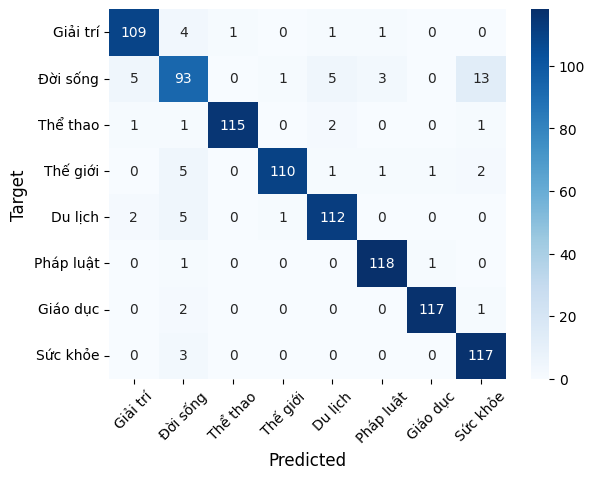

In [ ]:
plot_cm(confusion_matrix(y_valid, y_valid_pred))

### Đánh giá trên tập test

In [ ]:
best_rf = grid_search.best_estimator_
y_test_pred = best_rf.predict(X_test_features)

print("Test set accuracy: ", f"{accuracy_score(y_test, y_test_pred):.4f}")
print("Test set f1-score: ", f"{f1_score(y_test, y_test_pred, average='weighted'):.4f}")

Test set accuracy:  0.9193
Test set f1-score:  0.9171


In [ ]:
print(classification_report(y_test, y_test_pred, target_names=class_names))

              precision    recall  f1-score   support

    Giải trí       0.92      0.94      0.93       127
    Đời sống       0.89      0.70      0.78       132
    Thể thao       0.96      0.99      0.97       139
    Thế giới       0.96      0.88      0.92       139
     Du lịch       0.92      0.95      0.93       132
   Pháp luật       0.92      0.97      0.95       145
    Giáo dục       0.88      0.98      0.93       129
    Sức khỏe       0.90      0.94      0.92       147

    accuracy                           0.92      1090
   macro avg       0.92      0.92      0.92      1090
weighted avg       0.92      0.92      0.92      1090



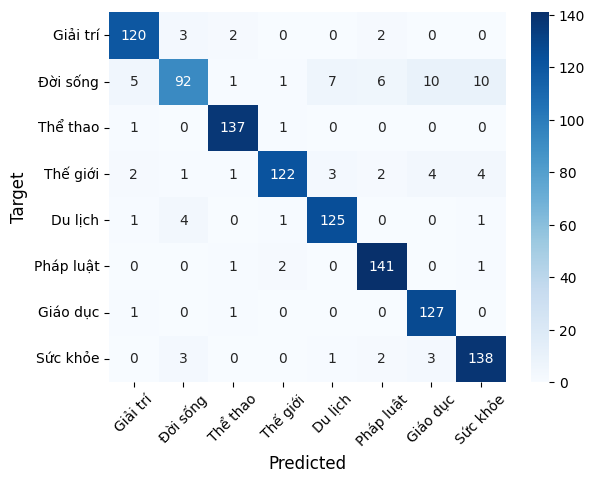

In [ ]:
plot_cm(confusion_matrix(y_test, y_test_pred))